In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

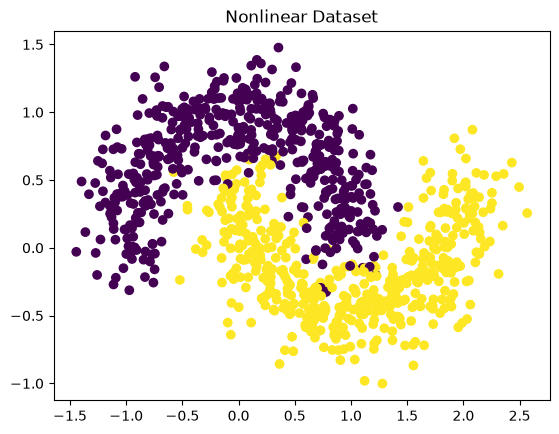

In [4]:
X, y = make_moons(
    n_samples=1000,
    noise=0.2,
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Nonlinear Dataset")
plt.show()

In [5]:
model = keras.Sequential([
    layers.Input(shape=(2,)),

    layers.Dense(16, activation="relu"),

    layers.Dense(32, activation="relu"),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

In [6]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [7]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7094 - loss: 0.6360 - val_accuracy: 0.7563 - val_loss: 0.5943
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7984 - loss: 0.5595 - val_accuracy: 0.7937 - val_loss: 0.5212
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8375 - loss: 0.4836 - val_accuracy: 0.8250 - val_loss: 0.4507
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8469 - loss: 0.4084 - val_accuracy: 0.8375 - val_loss: 0.3849
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8656 - loss: 0.3495 - val_accuracy: 0.8375 - val_loss: 0.3419
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8672 - loss: 0.3164 - val_accuracy: 0.8438 - val_loss: 0.3175
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8719 - loss: 0.3002 - val_accuracy: 0.8438 - val_loss: 0.3040
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8734 - loss: 0.2912 - val_accuracy: 0.8562 - v

In [8]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9900 - loss: 0.0478
Test Loss: 0.047779541462659836
Test Accuracy: 0.9900000095367432


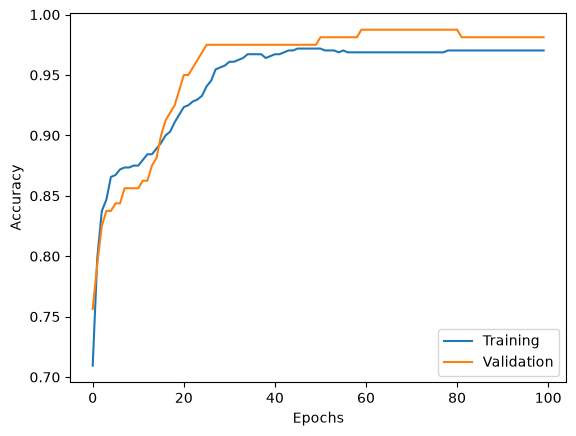

In [9]:
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()